# 5.5

In [1]:
import numpy as np
import matplotlib.pyplot as plt

f = lambda t: -0.5 * np.cos(2 * t) + 3.5
df = lambda t: np.sin(2 * t)

print(f"f(0) = {f(0):.4f}")
print(f"f'(0) = {df(0):.4f}")


f(0) = 3.0000
f'(0) = 0.0000


# 5.9
I'm not sure if my understanding is correct, but I try to approach solutions with Euler's method

Euler:  [6.000e+00 3.000e+00 1.500e+00 7.500e-01 3.750e-01 1.875e-01 9.375e-02
 4.688e-02 2.344e-02 1.172e-02 5.860e-03]
exact:  [6.      3.63918 2.20728 1.33878 0.81201 0.49251 0.29872 0.18118 0.10989
 0.06665 0.04043]


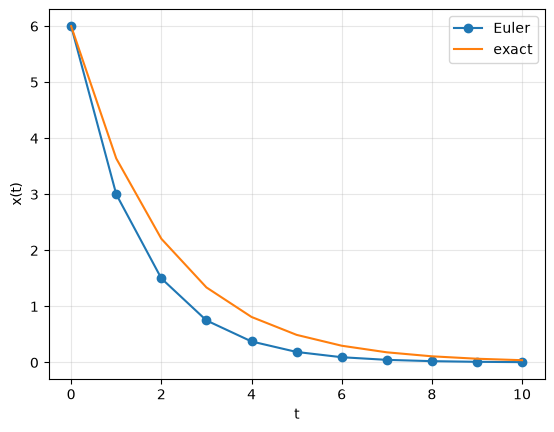

In [2]:
# Euler's method for x' = -0.5 x, starting at x(0) = 6.
dt = 1.0
t = np.arange(0, 11, dt)
x = np.zeros_like(t)
x[0] = 6.0
for n in range(len(t) - 1):
    x[n + 1] = x[n] + dt * (-0.5 * x[n])

exact = 6 * np.exp(-0.5 * t)
print("Euler: ", np.round(x, 5))
print("exact: ", np.round(exact, 5))

plt.plot(t, x, "o-", label="Euler")
plt.plot(t, exact, label="exact")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Maybe since we assume the slope is constant from t = 0 to 10, the actual function is a curve with changing slopes?

We use straight lines to connect the points because Euler's method approximates the solution by linearly interpolating between points using the slope given by the differential equation.

Upon visual inspection of the approximate solutions, they diverge from the exact solution over time, especially if the exact solution curve is not straight.

It allows us to see how well our straight-line approximations align with the actual slopes of the solution at each point, and this help us to assess the accuracy of applied method.

# 5.12

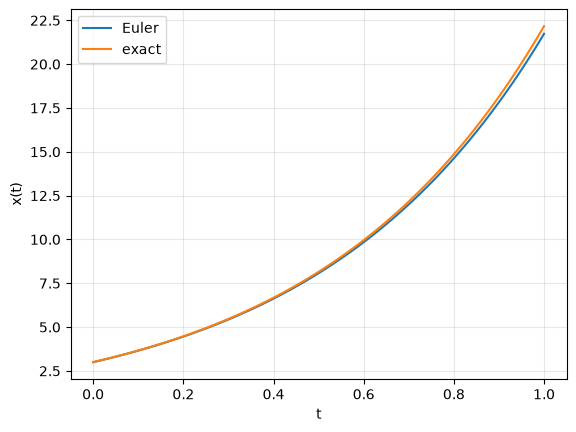

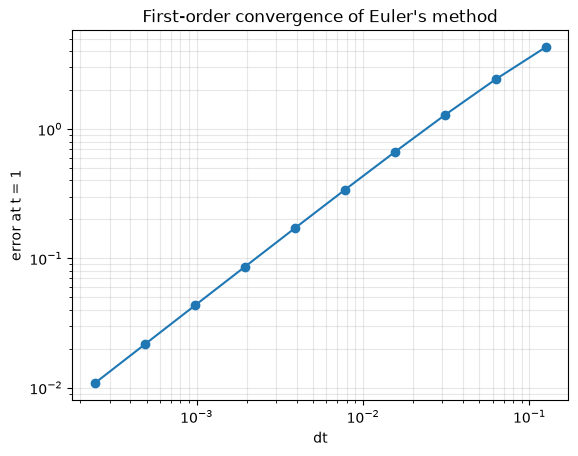

In [3]:
def euler(f, x0, t0, tmax, dt):
    """Explicit Euler for x' = f(t, x)."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        x[n + 1] = x[n] + dt * f(t[n], x[n])
    return t, x


f = lambda t, x: 2 * x
x0 = 3
t, x = euler(f, x0, 0, 1, 0.01)

plt.plot(t, x, label="Euler")
plt.plot(t, 3 * np.exp(2 * t), label="exact")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Error decreases linearly with dt.
H = 2.0 ** (-np.arange(3, 13))
errors = []
for dt in H:
    t, x = euler(f, x0, 0, 1, dt)
    errors.append(abs(x[-1] - 3 * np.exp(2)))

plt.loglog(H, errors, "o-")
plt.xlabel("dt")
plt.ylabel("error at t = 1")
plt.title("First-order convergence of Euler's method")
plt.grid(which="both", alpha=0.3)
plt.show()


# 5.13

Euler:     [6.000e+00 3.000e+00 1.500e+00 7.500e-01 3.750e-01 1.875e-01 9.375e-02
 4.688e-02 2.344e-02 1.172e-02 5.860e-03]
midpoint:  [6.      3.75    2.34375 1.46484 0.91553 0.5722  0.35763 0.22352 0.1397
 0.08731 0.05457]
exact:     [6.      3.63918 2.20728 1.33878 0.81201 0.49251 0.29872 0.18118 0.10989
 0.06665 0.04043]


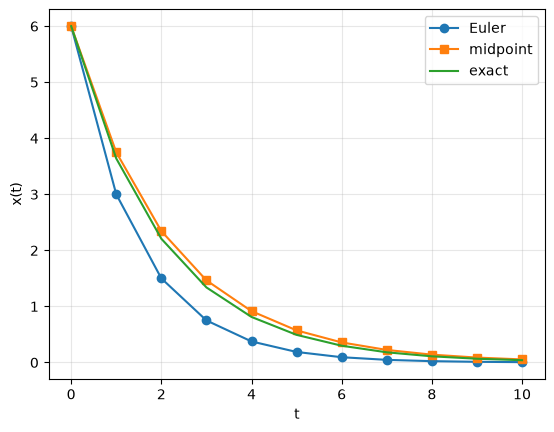

In [4]:
def midpoint(f, x0, t0, tmax, dt):
    """Second-order Runge-Kutta (midpoint) method."""
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros_like(t, dtype=float)
    x[0] = x0
    for n in range(len(t) - 1):
        half = x[n] + 0.5 * dt * f(t[n], x[n])
        x[n + 1] = x[n] + dt * f(t[n] + 0.5 * dt, half)
    return t, x


f = lambda t, x: -0.5 * x
t, x_euler = euler(f, 6, 0, 10, 1)
t, x_midpoint = midpoint(f, 6, 0, 10, 1)
exact = 6 * np.exp(-0.5 * t)

print("Euler:    ", np.round(x_euler, 5))
print("midpoint: ", np.round(x_midpoint, 5))
print("exact:    ", np.round(exact, 5))

plt.plot(t, x_euler, "o-", label="Euler")
plt.plot(t, x_midpoint, "s-", label="midpoint")
plt.plot(t, exact, label="exact")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
